# Non-diffracting beams: Bessel and Airy beams, and how they heal

Every beam of finite width spreads: a Gaussian beam of waist $w_0$ keeps
its size only over the Rayleigh range $z_R = \pi w_0^2/\lambda$, and the
narrower the spot, the faster it goes. Two families of beams appear to
break this rule. A **Bessel beam** keeps a central spot of a few
wavelengths over a distance many times its Rayleigh range (Durnin 1987),
and an **Airy beam** keeps its shape too, but its main lobe travels on a
*parabola*, although no force acts on the light (Berry and Balazs 1979,
Siviloglou and Christodoulides 2007). Both have a third property that has
made them popular in light sheet microscopy and laser machining: block the
central spot with an obstacle, and a little further on it is back. The
beams **heal themselves**.

None of this breaks a law of optics, and this notebook shows where the
tricks are hidden. In both cases the spot is not made by the light that
is in it, but by light that arrives from the side. A Bessel beam is a cone
of plane waves that keeps crossing the axis; an Airy beam is a family of
straight rays whose envelope, the caustic, is a parabola. Light that
passes beside an obstacle rebuilds the spot behind it, and the ray picture
predicts how far behind.

Sections: 0. the two setups (drawn with `pyoptics.sketch`); 1. the Bessel
zone behind an axicon, against a Gaussian beam with the same spot;
2. where the power of a Bessel beam is; 3. a Bessel beam heals behind an
obstacle; 4. the Airy beam: made by a cubic phase and a lens, bent on a
parabola, and compared with the exact solution; 5. an Airy beam heals.

All fields are propagated with the exact angular spectrum method
(`propagators.rayleigh_sommerfeld_I_TF_planes()`, many planes per call),
the analytic results (stationary phase, $J_0$, the Airy solution of the
paraxial wave equation and the ray caustics) are only used for comparison.
Scalar propagation is introduced in notebook [01](01_propagation.ipynb),
Gaussian beams in [06](06_gaussian_beams.ipynb), the caustics of rays and
waves in [47](47_rays_and_waves.ipynb). Conventions:
$e^{i(\mathbf{k}\cdot\mathbf{r}-\omega t)}$, lengths in micrometres
(distances along $z$ are plotted in mm).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap, PowerNorm
from scipy.optimize import brentq
from scipy.special import airy, j0, j1, ai_zeros

from pyoptics import sketch
from pyoptics.propagators import rayleigh_sommerfeld_I_TF_planes, fraunhofer_scaled
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1),
                       name="light")         # magma_r, fading to white at zero
t_start = time.time()

WL = 0.6328                     # HeNe, um
K = 2*np.pi/WL


def Ai(s):
    return airy(s)[0]


def scan(u0, x, y, zs, section, keep=(), crop=np.s_[:, :], measure=None, batch=8):
    """Propagate u0 to the distances zs (in batches of planes) and return the
    intensity on a line through each plane (section(u) picks it), the fields
    at the indices keep (cut to crop), and measure(u) for every plane."""

    rows, full, values = [], {}, []
    for i0 in range(0, len(zs), batch):
        planes, _, _ = rayleigh_sommerfeld_I_TF_planes(u0, x, y, zs[i0:i0 + batch], WL)
        for j, u in enumerate(planes, start=i0):
            rows.append(np.abs(section(u))**2)
            if j in keep:
                full[j] = u[crop].copy()
            if measure is not None:
                values.append(measure(u))
    return np.array(rows), full, values


def fwhm_centre(row, x):
    """Full width at half maximum of the central lobe of a symmetric profile
    (x = 0 at index N//2)."""

    c = len(x)//2
    i = c + np.argmax(row[c:] < row[c]/2)
    xh = np.interp(row[c]/2, [row[i], row[i - 1]], [x[i], x[i - 1]])
    return 2*xh

## 0. Two ways to beat diffraction

**The axicon** (McLeod 1954) is a glass cone. It tilts every ray of a
collimated beam towards the axis by the same angle $\theta$, so the upper
half of the beam crosses the lower half in a diamond, the Bessel zone,
which ends at $z_{\max} = w/\tan\theta$ for a beam of radius $w$. In each
plane of the zone the light arrives on a cone of directions, and the
superposition of these plane waves is the Bessel function
$J_0(k\sin\theta\, r)$. An opaque disk of radius $a$ in the zone takes
away the rays that would have reached the axis in a short stretch behind
it, its geometric shadow of length $a/\tan\theta$ (white triangle). Behind
the shadow the axis is fed by rays that passed beside the disk (top).

**The cubic phase plate.** An Airy beam is the Fourier transform of a
Gaussian beam with a cubic phase $\propto \xi^3$, so a phase plate or a
spatial light modulator followed by a lens makes one in the back focal
plane (Siviloglou et al. 2007). The cubic phase tilts each ray by an angle
$\propto \xi^2$, in the same direction for both halves of the beam. Behind
the lens the rays no longer meet in a focus: they touch a parabola, the
caustic, and that is where the main lobe of the Airy beam runs (bottom).

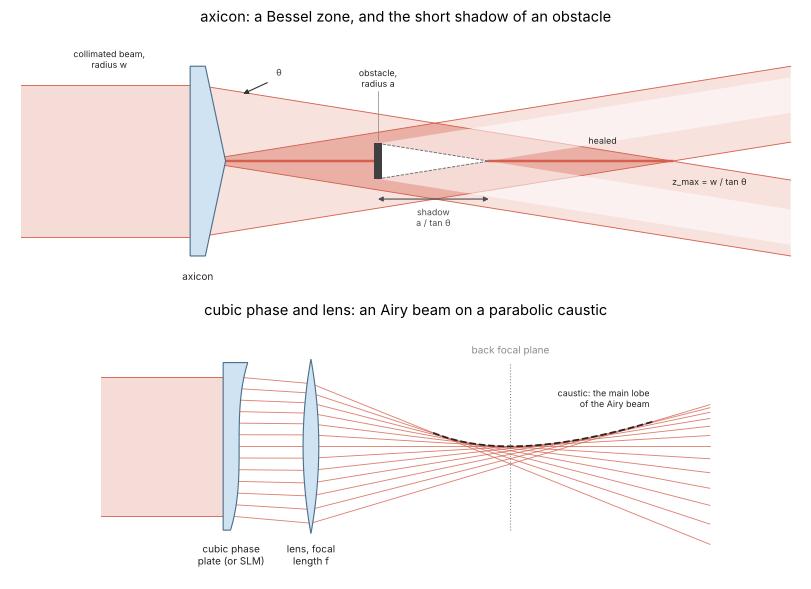

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5))
sketch.axicon_bessel(axes[0], title="axicon: a Bessel zone, and the short shadow of an obstacle")
sketch.cubic_phase_airy(axes[1], title="cubic phase and lens: an Airy beam on a parabolic caustic")
plt.tight_layout()

## 1. The Bessel zone behind an axicon

A thin axicon multiplies the field by $e^{-ik\sin\theta\,r}$: a conical
phase. Illuminated with a collimated Gaussian beam of 1 mm radius and a
deflection angle of $\theta = 0.5°$, it makes a Bessel zone of
$z_{\max} = w/\tan\theta$ = 115 mm. The radial wave number is $k_r =
k\sin\theta$, and the field near the axis is
$J_0(k_r r)$ with the first zero at $r_0 = 2.405/k_r$ = 28 um. (A
Gaussian envelope on a Bessel beam is called a Bessel-Gauss beam, Gori et
al. 1987.)

For comparison, a Gaussian beam is focused to a waist with the **same**
intensity FWHM as the central lobe of the Bessel beam, in the middle of
the Bessel zone, with the same power. Both are propagated on the same grid
(1024 × 1024 points of 4 um) to 161 planes.

In [3]:
N, L = 1024, 4096.0
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
R = np.hypot(X, Y)
c = N//2

THETA = np.deg2rad(0.5)         # deflection of the axicon
K_R = K*np.sin(THETA)           # radial wave number of the Bessel beam
W = 1000.0                      # 1/e radius of the illuminating beam (amplitude)
Z_MAX = W/np.tan(THETA)
R0 = 2.405/K_R                  # first zero of J0(k_r r)

u_bessel = np.exp(-(R/W)**2)*np.exp(-1j*K_R*R)

# Gaussian beam with the same intensity FWHM, focused at z_max/2
fwhm_j0 = 2*brentq(lambda s: j0(s)**2 - 0.5, 0.5, 2.0)/K_R
w0 = fwhm_j0/np.sqrt(2*np.log(2))
z_R = np.pi*w0**2/WL
q = -Z_MAX/2 - 1j*z_R           # q = z - i z_R, the waist at z = Z_MAX/2
u_gauss = (W/w0)*np.exp(1j*K*R**2/(2*q))*(-1j*z_R/q)   # the same power as u_bessel

zs = np.linspace(0, 1.4*Z_MAX, 161)
row = lambda u: u[c, :]
xz_b, _, _ = scan(u_bessel, x, y, zs, row)
xz_g, _, _ = scan(u_gauss, x, y, zs, row)

print("z_max = {:.1f} mm, k_r = {:.4f} rad/um, first zero r0 = {:.1f} um".format(
    Z_MAX/1e3, K_R, R0))
print("same FWHM {:.1f} um: Gaussian waist w0 = {:.1f} um, Rayleigh range z_R = {:.2f} mm, "
      "z_max/z_R = {:.0f}".format(fwhm_j0, w0, z_R/1e3, Z_MAX/z_R))

z_max = 114.6 mm, k_r = 0.0866 rad/um, first zero r0 = 27.8 um
same FWHM 26.0 um: Gaussian waist w0 = 22.1 um, Rayleigh range z_R = 2.42 mm, z_max/z_R = 47


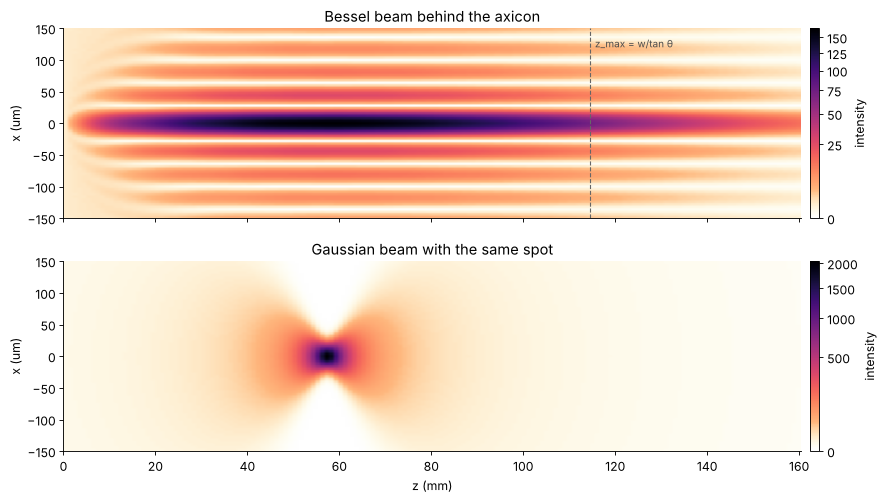

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True)
for ax, xz, name in zip(axes, (xz_b, xz_g), ("Bessel beam behind the axicon",
                                             "Gaussian beam with the same spot")):
    im = ax.imshow(xz.T, extent=(zs[0]/1e3, zs[-1]/1e3, x[0], x[-1]), aspect="auto",
                   origin="lower", cmap=LIGHT, norm=PowerNorm(0.5, vmin=0, vmax=xz.max()))
    ax.set_ylim(-150, 150)
    ax.set_ylabel("x (um)")
    ax.set_title(name)
    fig.colorbar(im, ax=ax, pad=0.01, label="intensity")
axes[0].axvline(Z_MAX/1e3, color="0.4", ls="--", lw=1)
axes[0].text(Z_MAX/1e3 + 1, 120, "z_max = w/tan θ", fontsize=9, color="0.3")
axes[1].set_xlabel("z (mm)")
plt.tight_layout()
plt.show()

The Bessel beam keeps a central lobe of the same size over the whole
zone and then fades out at $z_{\max}$, where the last rays from the rim of
the beam cross the axis. The Gaussian beam with the same spot is a short
flash around its waist: its Rayleigh range is 2.4 mm, 47 times shorter
than the Bessel zone. (Colours on a square root scale, each beam
normalized to its own peak.)

**The on-axis intensity** follows from the stationary phase: the ring of
the axicon at radius $\rho = z\tan\theta$ sends its light to the axis at
$z$, and the ring area grows with $\rho$. For an incident amplitude
$A(\rho)$ the result is (Herman and Wiggins 1991)

$$I(0, z) \approx 2\pi k \sin^2\theta\; z\, |A(z\tan\theta)|^2,$$

a linear rise, then the Gaussian fall-off of the illumination. With the
same power, the Gaussian beam peaks more than ten times higher on the
axis, but only within a few millimetres of its waist. The width of the
central lobe is $2 \times 1.126/k_r$ for the Bessel beam, independent of
$z$, and $w(z)\sqrt{2\ln 2}$ for the Gaussian beam.

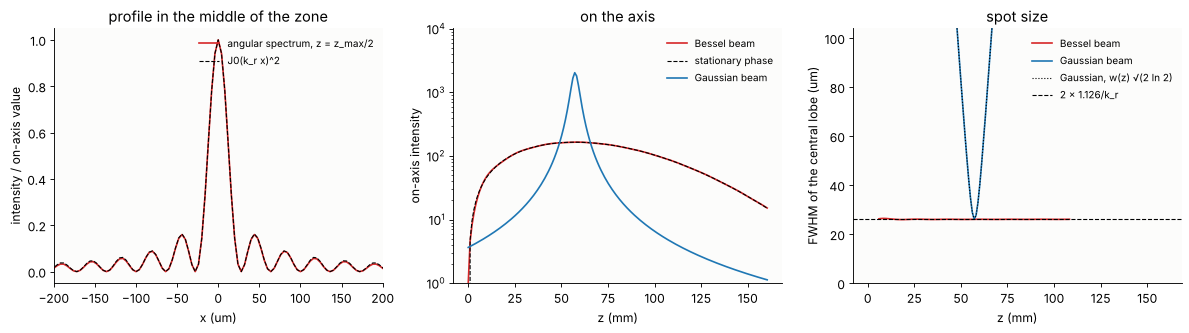

on-axis intensity: max deviation from the stationary phase result 0.69% of the peak (z between 20 and 139 mm)
FWHM over 10 % to 90 % of z_max: 25.9 to 26.3 um (J0^2: 26.0 um)


In [5]:
ax_b = xz_b[:, c]
ax_pred = 2*np.pi*K*np.sin(THETA)**2*zs*np.exp(-2*(zs*np.tan(THETA)/W)**2)
fw_b = np.array([fwhm_centre(r, x) for r in xz_b])
fw_g = np.array([fwhm_centre(r, x) for r in xz_g])
iz = np.argmin(abs(zs - Z_MAX/2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ax[0].plot(x, xz_b[iz]/xz_b[iz, c], color="C3", label="angular spectrum, z = z_max/2")
ax[0].plot(x, j0(K_R*np.abs(x))**2, "k--", lw=1, label="J0(k_r x)^2")
ax[0].set_xlim(-200, 200)
ax[0].set_xlabel("x (um)")
ax[0].set_ylabel("intensity / on-axis value")
ax[0].set_title("profile in the middle of the zone")
ax[0].legend(frameon=False, fontsize=9, loc="upper right")
ax[1].plot(zs/1e3, ax_b, color="C3", label="Bessel beam")
ax[1].plot(zs/1e3, ax_pred, "k--", lw=1, label="stationary phase")
ax[1].plot(zs/1e3, xz_g[:, c], color="C0", label="Gaussian beam")
ax[1].set_yscale("log")
ax[1].set_ylim(1, 5*xz_g[:, c].max())
ax[1].set_xlabel("z (mm)")
ax[1].set_ylabel("on-axis intensity")
ax[1].set_title("on the axis")
ax[1].legend(frameon=False, fontsize=9, loc="upper right")
inside = (zs > 0.05*Z_MAX) & (zs < 0.95*Z_MAX)
ax[2].plot(zs[inside]/1e3, fw_b[inside], color="C3", label="Bessel beam")
ax[2].plot(zs/1e3, fw_g, color="C0", label="Gaussian beam")
ax[2].plot(zs/1e3, fwhm_j0*np.sqrt(1 + ((zs - Z_MAX/2)/z_R)**2), "k:", lw=1,
           label="Gaussian, w(z) √(2 ln 2)")
ax[2].axhline(fwhm_j0, color="k", ls="--", lw=1, label="2 × 1.126/k_r")
ax[2].set_ylim(0, 4*fwhm_j0)
ax[2].set_xlabel("z (mm)")
ax[2].set_ylabel("FWHM of the central lobe (um)")
ax[2].set_title("spot size")
ax[2].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

err = np.abs(ax_b[20:140] - ax_pred[20:140]).max()/ax_pred.max()
print("on-axis intensity: max deviation from the stationary phase result {:.2%} "
      "of the peak (z between {:.0f} and {:.0f} mm)".format(err, zs[20]/1e3, zs[139]/1e3))
print("FWHM over 10 % to 90 % of z_max: {:.1f} to {:.1f} um (J0^2: {:.1f} um)".format(
    fw_b[(zs > 0.1*Z_MAX) & (zs < 0.9*Z_MAX)].min(),
    fw_b[(zs > 0.1*Z_MAX) & (zs < 0.9*Z_MAX)].max(), fwhm_j0))

The profile in the middle of the zone is $J_0^2$, and the on-axis
intensity follows the stationary phase result to within a small fraction
of a percent; the ripple near $z = 0$ comes from the edge of the axicon
region that is not yet in the stationary phase regime. The spot keeps its
size from close behind the axicon to near the end of the zone.

## 2. Where is the power?

The trade-off shows up when the power is counted. The **angular
spectrum** of the field behind the axicon is a thin ring at $|k_\perp| =
k_r$, with a width of about $2/W$ given by the illuminating beam: a cone
of plane waves, all of them at the same angle to the axis. An ideal Bessel
beam, an infinitely thin ring, would not change at all on propagation,
because every plane wave picks up the same phase $k_z z$ with $k_z =
k\cos\theta$. It would also carry infinite power, because
$J_0^2(k_r r) \approx 2/(\pi k_r r)\cos^2(\ldots)$ falls off so slowly that
each ring carries about the same power as the next.

The cumulative power $P(r)$ within a radius $r$ shows this for the real
beam: it grows in nearly equal steps, one per ring, until the Gaussian
envelope of the illumination cuts it off. The central lobe that makes the
long narrow focus holds a small share of the power, the rest is in the
rings that are needed to rebuild it further on.

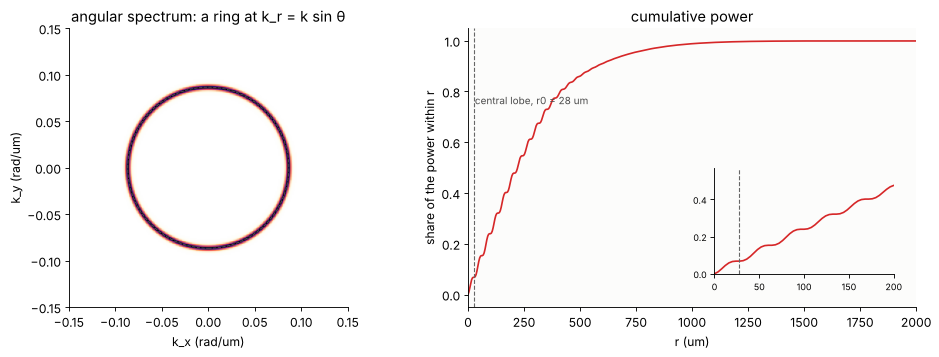

share of the power in the central lobe (r < r0) at z_max/2: 6.78%
rings within the beam: about W k_r/pi = 28


In [6]:
# angular spectrum behind the axicon
spec = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(u_bessel)))
kx = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(N, x[1] - x[0]))
# power within radius r at z_max/2 (rotationally symmetric: from the x section)
xp = x[c:]
dr = xp[1] - xp[0]
P = np.cumsum(xz_b[iz, c:]*2*np.pi*xp*dr)
P_total = np.pi*W**2/2              # power of the incident Gaussian, |u|^2 = exp(-2 r^2/W^2)
P_core = np.interp(R0, xp, P)

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
im = ax[0].imshow(np.abs(spec)**2, extent=(kx[0], kx[-1], kx[0], kx[-1]), origin="lower",
                  cmap=LIGHT)
ax[0].set_xlim(-0.15, 0.15)
ax[0].set_ylim(-0.15, 0.15)
ax[0].add_patch(plt.Circle((0, 0), K_R, fill=False, ls="--", color="0.3", lw=0.8))
ax[0].set_xlabel("k_x (rad/um)")
ax[0].set_ylabel("k_y (rad/um)")
ax[0].set_title("angular spectrum: a ring at k_r = k sin θ")
ax[1].plot(xp, P/P_total, color="C3", label="P(r) / total power, z = z_max/2")
ax[1].axvline(R0, color="0.4", ls="--", lw=1)
ax[1].text(R0*1.1, 0.75, "central lobe, r0 = {:.0f} um".format(R0), fontsize=9, color="0.3")
ax[1].set_xlabel("r (um)")
ax[1].set_ylabel("share of the power within r")
ax[1].set_xlim(0, 2000)
ax[1].set_title("cumulative power")
ax_in = ax[1].inset_axes([0.55, 0.12, 0.4, 0.38])
ax_in.plot(xp, P/P_total, color="C3")
ax_in.axvline(R0, color="0.4", ls="--", lw=1)
ax_in.set_xlim(0, 200)
ax_in.set_ylim(0, 1.2*np.interp(200, xp, P/P_total))
ax_in.tick_params(labelsize=8)
plt.tight_layout()
plt.show()
print("share of the power in the central lobe (r < r0) at z_max/2: {:.2%}".format(
    P_core/P_total))
print("rings within the beam: about W k_r/pi = {:.0f}".format(W*K_R/np.pi))

Only about 7 % of the power is in the central lobe, about as much as in
each of the next rings, and the number of rings is about the beam radius
divided by the ring spacing $\pi/k_r$ (the steps get smaller further out,
where the Gaussian illumination is weaker). A Bessel beam buys its depth of focus with power in the side
lobes. For imaging with a Bessel beam (light sheets, laser scanning) this
is the price: the rings illuminate the sample too, which costs contrast
unless they are suppressed, for example by confocal detection or
two-photon excitation.

## 3. A Bessel beam heals behind an obstacle

An opaque disk of radius $a = 3 r_0$ = 83 um is placed on the axis at
$z_0 = 0.3\, z_{\max}$ = 34 mm. It takes out the central lobe and the
first two rings. The rays that would have crossed the axis behind it are
those that hit the disk; rays of the cone that pass the disk at the radius
$a$ reach the axis after

$$\Delta z_{\rm shadow} = \frac{a}{\tan\theta} \approx 9.5\ \mathrm{mm}.$$

Behind that distance every ray that reaches the axis has passed beside the
disk, and the beam is whole again (Bouchal et al. 1998). The field at
$z_0$ is multiplied by the transmission of the disk and propagated
onward. The healing is measured by the overlap of the obstructed with the
undisturbed field within $r < 3 r_0$,
$\eta = |\langle u, u_{\rm free}\rangle|^2 / (\|u\|^2 \|u_{\rm free}\|^2)$,
which is 1 when both have the same shape there.

In [7]:
A_OBST = 3*R0
Z0 = 0.3*Z_MAX
L_SHADOW = A_OBST/np.tan(THETA)
dzs = np.linspace(0, 1.4*Z_MAX - Z0, 121)
snap_dz = np.array([0.02, 0.5, 1.0, 2.0, 4.0])*L_SHADOW   # snapshots behind the disk
snap = [np.argmin(abs(dzs - d)) for d in snap_dz]
core = R < 3*R0
win = slice(c - 40, c + 40)

planes_z0, _, _ = rayleigh_sommerfeld_I_TF_planes(u_bessel, x, y, [Z0], WL)
u_z0 = planes_z0[0]
blocked = (R < A_OBST)
u_obst = u_z0*~blocked
xz_o, full_o, core_o = scan(u_obst, x, y, dzs, row, keep=snap,
                            measure=lambda u: u[core])
xz_f, full_f, core_f = scan(u_z0, x, y, dzs, row, keep=snap,
                            measure=lambda u: u[core])
eta = np.array([abs(np.vdot(a, b))**2/(np.vdot(a, a).real*np.vdot(b, b).real)
                for a, b in zip(core_o, core_f)])
P_blocked = np.sum(np.abs(u_z0[blocked])**2)/np.sum(np.abs(u_z0)**2)
print("obstacle radius a = {:.0f} um at z0 = {:.1f} mm, shadow a/tan θ = {:.1f} mm".format(
    A_OBST, Z0/1e3, L_SHADOW/1e3))
print("share of the power blocked: {:.2%}".format(P_blocked))

obstacle radius a = 83 um at z0 = 34.4 mm, shadow a/tan θ = 9.5 mm
share of the power blocked: 16.79%


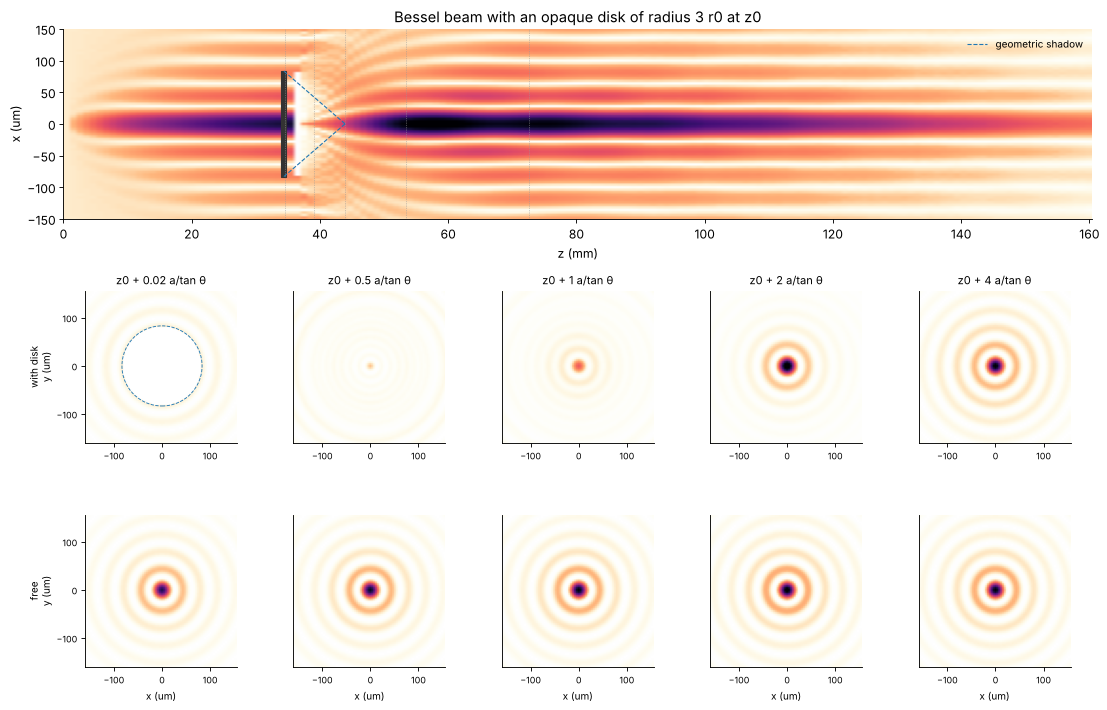

In [8]:
fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(3, 5, height_ratios=(1.25, 1, 1))
ax = fig.add_subplot(gs[0, :])
i_before = zs < Z0
z_all = np.r_[zs[i_before], Z0 + dzs]/1e3
xz_all = np.r_[xz_b[i_before], xz_o]
ax.imshow(xz_all.T, extent=(z_all[0], z_all[-1], x[0], x[-1]), aspect="auto", origin="lower",
          cmap=LIGHT, norm=PowerNorm(0.5, vmin=0, vmax=xz_b.max()))
ax.add_patch(plt.Rectangle((Z0/1e3 - 0.4, -A_OBST), 0.8, 2*A_OBST, color="0.2"))
zz = np.array([Z0, Z0 + L_SHADOW])/1e3
ax.plot(zz, [A_OBST, 0], "--", color="C0", lw=1)
ax.plot(zz, [-A_OBST, 0], "--", color="C0", lw=1, label="geometric shadow")
for d in snap_dz:
    ax.axvline((Z0 + d)/1e3, color="0.6", lw=0.6, ls=":")
ax.set_ylim(-150, 150)
ax.set_xlabel("z (mm)")
ax.set_ylabel("x (um)")
ax.set_title("Bessel beam with an opaque disk of radius 3 r0 at z0")
ax.legend(frameon=False, fontsize=9, loc="upper right")
ext = (x[win][0], x[win][-1], y[win][0], y[win][-1])
vmax = np.abs(full_f[snap[2]][win, win]).max()**2
for j, (i, d) in enumerate(zip(snap, snap_dz)):
    for k, (full, name) in enumerate(((full_o, "with disk"), (full_f, "free"))):
        a = fig.add_subplot(gs[1 + k, j])
        a.imshow(np.abs(full[i][win, win])**2, extent=ext, origin="lower", cmap=LIGHT,
                 vmin=0, vmax=vmax)
        a.set_xticks([-100, 0, 100])
        a.set_yticks([-100, 0, 100] if j == 0 else [])
        a.tick_params(labelsize=8)
        if k == 0:
            a.set_title("z0 + {:.2g} a/tan θ".format(d/L_SHADOW), fontsize=10)
            if j == 0:
                a.add_patch(plt.Circle((0, 0), A_OBST, fill=False, ls="--", color="C0", lw=0.8))
        if j == 0:
            a.set_ylabel(name + "\ny (um)", fontsize=9)
        if k == 1:
            a.set_xlabel("x (um)", fontsize=9)
plt.tight_layout()
plt.show()

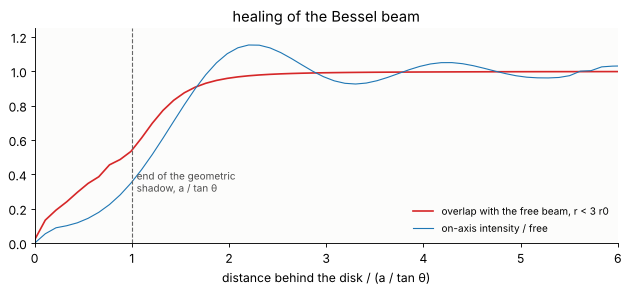

overlap at 1 and 2 shadow lengths: 0.534, 0.959; on-axis intensity / free: 0.35, 1.10


In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(dzs/L_SHADOW, eta, color="C3", label="overlap with the free beam, r < 3 r0")
ax.plot(dzs/L_SHADOW, xz_o[:, c]/xz_f[:, c], color="C0", lw=1, label="on-axis intensity / free")
ax.axvline(1, color="0.4", ls="--", lw=1)
ax.text(1.05, 0.3, "end of the geometric\nshadow, a / tan θ", fontsize=9, color="0.3")
ax.set_xlabel("distance behind the disk / (a / tan θ)")
ax.set_ylim(0, 1.25)
ax.set_xlim(0, 6)
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.set_title("healing of the Bessel beam")
plt.tight_layout()
plt.show()
i1 = np.argmin(abs(dzs - L_SHADOW))
i2 = np.argmin(abs(dzs - 2*L_SHADOW))
print("overlap at 1 and 2 shadow lengths: {:.3f}, {:.3f}; on-axis intensity / free: "
      "{:.2f}, {:.2f}".format(eta[i1], eta[i2], xz_o[i1, c]/xz_f[i1, c],
                              xz_o[i2, c]/xz_f[i2, c]))

Right behind the disk there is a hole, and in it a weak spot on the axis:
the spot of Arago and Poisson (notebook [01](01_propagation.ipynb)), made
by the light diffracted at the edge of the disk. At the end of the
geometric shadow the central lobe is half back (overlap 0.5), and after
two shadow lengths the overlap with the undisturbed beam is 0.96: the ray
picture gives the distance, diffraction at the edge of the disk smooths
the transition over about one more shadow length. The disk blocked 17 %
of the power, the central lobe and the first two rings, and still the
beam behind it looks like the undisturbed one. What the obstacle removed
was the light that the axis *would have* received over the next few
millimetres (it is missing further out, in the rings, later on); the light
for the rest of the zone passed beside it.

This is the property that makes Bessel beams useful as light sheets in
scattering tissue (Fahrbach et al. 2010): a cell in the way casts a short
shadow instead of a long stripe.

## 4. The Airy beam

### Made by a cubic phase and a lens

The paraxial wave equation in one transverse dimension,
$i\,\partial_\xi u + \tfrac12\partial_s^2 u = 0$ with $s = x/x_0$ and
$\xi = z/(k x_0^2)$, has the non-spreading solution $u =
\mathrm{Ai}(s - \xi^2/4)\,e^{i(s\xi/2 - \xi^3/12)}$: the Airy function
with a fixed shape, shifted sideways by $x_0\xi^2/4$ (Berry and Balazs
1979). Like the ideal Bessel beam, it carries infinite power. The
finite-energy version starts with $\mathrm{Ai}(s)\,e^{as}$, $a \ll 1$,
whose Fourier transform is a Gaussian times a cubic phase. The field
$e^{-\xi^2/w^2}e^{-i\xi^3/(3\xi_0^3)}$ in front of a lens of focal length
$f$ gives in the back focal plane

$$u(x) \propto \mathrm{Ai}\!\left(\frac{x}{x_0} + a^2\right)e^{a x/x_0},
\qquad x_0 = \frac{f}{k\xi_0}, \quad a = \frac{\xi_0^2}{w^2}.$$

A 2D cubic phase $\xi^3 + \eta^3$ gives the product of two such Airy
functions in $x$ and $y$. Below the field in the back focal plane is
computed with `fraunhofer_scaled()` (a lens maps the angular spectrum to
the back focal plane, which is the Fraunhofer integral at the distance
$f$) for $x_0$ = 20 um, $a$ = 0.05 and $f$ = 200 mm.

In [10]:
X0, A_AIRY = 20.0, 0.05
F_LENS = 200e3                  # 200 mm
XI0 = F_LENS/(K*X0)
W_PUPIL = XI0/np.sqrt(A_AIRY)
Np, Lp = 1024, 5*W_PUPIL
xp_, yp_, XP, YP = grid2d(-Lp/2, Lp/2, -Lp/2, Lp/2, Np)
pupil = np.exp(-(XP**2 + YP**2)/W_PUPIL**2)*np.exp(-1j*((XP/XI0)**3 + (YP/XI0)**3)/3)
x_out = np.linspace(-25*X0, 6*X0, 320)
u_f, _, _ = fraunhofer_scaled(pupil, xp_, yp_, F_LENS, WL, x_out, x_out)
I_f = np.abs(u_f)**2
a1d = Ai(x_out/X0 + A_AIRY**2)*np.exp(A_AIRY*x_out/X0)
print("phase plate: xi0 = {:.0f} um, Gaussian radius w = {:.2f} mm, cubic phase at the "
      "1/e^2 radius w: {:.0f} rad".format(XI0, W_PUPIL/1e3, (W_PUPIL/XI0)**3/3))

phase plate: xi0 = 1007 um, Gaussian radius w = 4.50 mm, cubic phase at the 1/e^2 radius w: 30 rad


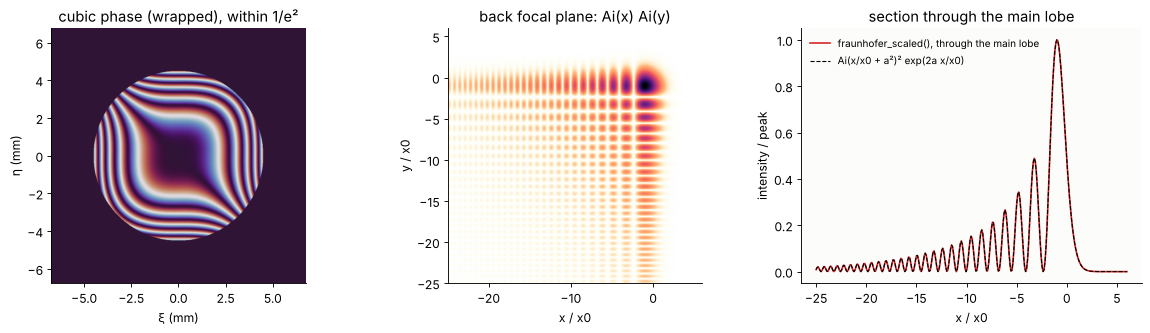

max deviation of the section from Ai^2: 9.8e-06 of the peak


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ax[0].imshow(np.angle(pupil)*(np.abs(pupil)**2 > np.exp(-2)), extent=(xp_[0]/1e3, xp_[-1]/1e3,
             yp_[0]/1e3, yp_[-1]/1e3), origin="lower", cmap="twilight")
ax[0].set_xlim(-1.5*W_PUPIL/1e3, 1.5*W_PUPIL/1e3)
ax[0].set_ylim(-1.5*W_PUPIL/1e3, 1.5*W_PUPIL/1e3)
ax[0].set_xlabel("ξ (mm)")
ax[0].set_ylabel("η (mm)")
ax[0].set_title("cubic phase (wrapped), within 1/e²")
ext = (x_out[0]/X0, x_out[-1]/X0, x_out[0]/X0, x_out[-1]/X0)
ax[1].imshow(I_f, extent=ext, origin="lower", cmap=LIGHT, norm=PowerNorm(0.5))
ax[1].set_xlabel("x / x0")
ax[1].set_ylabel("y / x0")
ax[1].set_title("back focal plane: Ai(x) Ai(y)")
i_main = np.unravel_index(np.argmax(I_f), I_f.shape)[0]
ax[2].plot(x_out/X0, I_f[i_main]/I_f[i_main].max(), color="C3",
           label="fraunhofer_scaled(), through the main lobe")
ax[2].plot(x_out/X0, a1d**2/(a1d**2).max(), "k--", lw=1, label="Ai(x/x0 + a²)² exp(2a x/x0)")
ax[2].set_xlabel("x / x0")
ax[2].set_ylabel("intensity / peak")
ax[2].set_title("section through the main lobe")
ax[2].legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()
print("max deviation of the section from Ai^2: {:.1e} of the peak".format(
    np.abs(I_f[i_main]/I_f[i_main].max() - a1d**2/(a1d**2).max()).max()))

### A beam that bends

The Airy field in the back focal plane is the start of the propagation,
now written down directly, $u(x, y, 0) = \mathrm{Ai}(x/x_0)\,e^{ax/x_0}\,
\mathrm{Ai}(y/x_0)\,e^{ay/x_0}$, on a grid of 2048 × 2048 points of
2.5 um, and propagated over $\xi = 0 \ldots 8$, i.e. 32 mm. The exact solution of
the paraxial wave equation for the finite-energy beam is (Siviloglou and
Christodoulides 2007)

$$u(s, \xi) = \mathrm{Ai}\!\left(s - \frac{\xi^2}{4} + ia\xi\right)
\exp\!\left(as - \frac{a\xi^2}{2} - \frac{i\xi^3}{12} + \frac{ia^2\xi}{2}
+ \frac{is\xi}{2}\right),$$

in $x$ and in $y$. The main lobe runs on the parabola $x = x_0(\xi^2/4 +
s_1)$, $s_1 = -1.019$ the maximum of Ai, at 45° between the $x$ and $y$
axes; the figures show the diagonal $x = y$ through the beam.

**The rays.** Far from the main lobe $\mathrm{Ai}(-\sigma) \approx
\pi^{-1/2}\sigma^{-1/4}\sin(\tfrac23\sigma^{3/2} + \pi/4)$: two local plane
waves whose transverse wave number $\pm\sqrt{\sigma}/x_0$ grows with the
distance $\sigma$ from the main lobe. Each point $x_i = -x_0t^2$ sends out
a ray in the direction $t/(kx_0)$ (and one in $-t/(kx_0)$), which follows
$x = x_0(-t^2 + t\xi)$, a straight line. All of these lines are tangent to
the parabola $x = x_0\xi^2/4$, touching it at $\xi = 2t$: the parabola is
the **caustic** of a family of straight rays, and the main lobe is the
bright edge of the caustic, as in notebook [47](47_rays_and_waves.ipynb).
Nothing bends; the light that makes the main lobe at $\xi$ came from the
side lobe at $x_i = -x_0\xi^2/4$.

In [12]:
Na, La = 2048, 5120.0
xa, ya, XA, YA = grid2d(-La/2, La/2, -La/2, La/2, Na)
ZA = K*X0**2                    # z for xi = 1
u_airy = (Ai(XA/X0)*np.exp(A_AIRY*XA/X0))*(Ai(YA/X0)*np.exp(A_AIRY*YA/X0))
xis = np.linspace(0, 8, 61)
snap_xi = (0.0, 2.0, 3.2, 5.0, 7.0)
snap_a = [np.argmin(abs(xis - s)) for s in snap_xi]
diag = lambda u: np.diagonal(u)
win_a = np.flatnonzero((xa/X0 > -10) & (xa/X0 < 20))
crop_a = np.ix_(win_a, win_a)


def centroid(u):
    I = np.abs(u)**2
    return (I.sum(axis=0) @ xa)/I.sum()


xz_a, full_a, cen = scan(u_airy, xa, ya, xis*ZA, diag, keep=snap_a, crop=crop_a,
                         measure=centroid)
cen = np.array(cen)


def airy_exact(s, xi, a=A_AIRY):
    return Ai(s - xi**2/4 + 1j*a*xi)*np.exp(a*s - a*xi**2/2 - 1j*xi**3/12
                                            + 1j*a**2*xi/2 + 1j*s*xi/2)


s1 = ai_zeros(1)[1][0]          # position of the maximum of Ai
I0_exact = (np.abs(airy_exact(xa/X0, 0.0))**4).max()
errs = []
for i in snap_a:
    exact = np.abs(airy_exact(xa/X0, xis[i]))**4       # diagonal: |u(s)|^2 in x times in y
    errs.append(np.abs(xz_a[i]/xz_a[0].max() - exact/I0_exact).max())
print("x0 = {} um, a = {}: k x0^2 = {:.2f} mm per unit of xi, deflection at xi = 8: "
      "{:.0f} um".format(X0, A_AIRY, ZA/1e3, X0*64/4))
print("max deviation of the diagonal intensity from the exact solution (of the peak at z = 0): "
      + ", ".join("xi = {:.1f}: {:.1e}".format(xis[i], e) for i, e in zip(snap_a, errs)))
print("centroid of the intensity: {:.3f} to {:.3f} um over xi = 0 ... 8".format(
    cen.min(), cen.max()))

x0 = 20.0 um, a = 0.05: k x0^2 = 3.97 mm per unit of xi, deflection at xi = 8: 320 um
max deviation of the diagonal intensity from the exact solution (of the peak at z = 0): xi = 0.0: 1.1e-14, xi = 2.0: 1.2e-04, xi = 3.2: 3.9e-04, xi = 4.9: 9.5e-04, xi = 6.9: 1.1e-03
centroid of the intensity: -99.949 to -99.063 um over xi = 0 ... 8


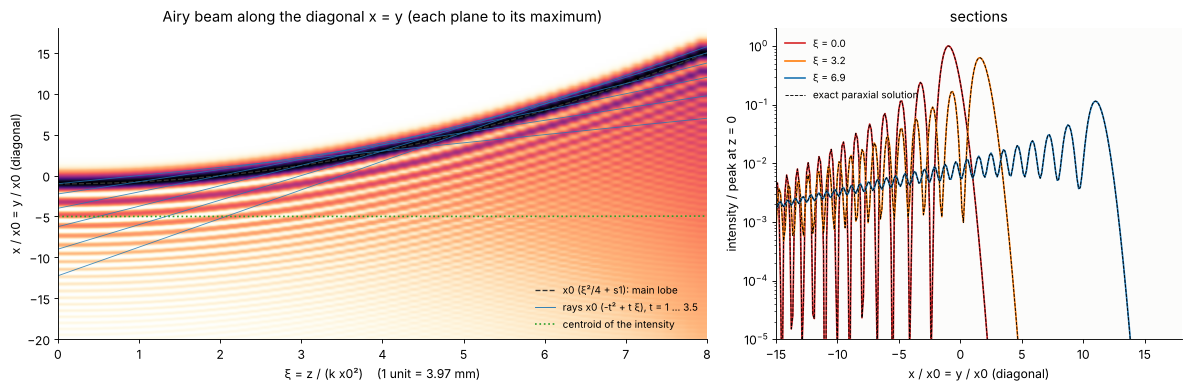

In [13]:
s_d = xa/X0                         # diagonal: x = y = s x0
norm_planes = xz_a.max(axis=1, keepdims=True)   # each plane to its own maximum (the beam fades)
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": (1.6, 1)})
ax[0].imshow((xz_a/norm_planes).T, extent=(xis[0], xis[-1], s_d[0], s_d[-1]), aspect="auto",
             origin="lower", cmap=LIGHT, norm=PowerNorm(0.5, vmin=0, vmax=1))
xi_f = np.linspace(0, xis[-1], 200)
ax[0].plot(xi_f, xi_f**2/4 + s1, "--", color="0.2", lw=1.2, label="x0 (ξ²/4 + s1): main lobe")
for tt in (1.0, 1.5, 2.0, 2.5, 3.0, 3.5):
    ax[0].plot(xi_f, -tt**2 + tt*xi_f, color="C0", lw=0.8, alpha=0.8)
ax[0].plot([], [], color="C0", lw=0.8, label="rays x0 (-t² + t ξ), t = 1 ... 3.5")
ax[0].plot(xis, cen/X0, ":", color="C2", lw=1.5, label="centroid of the intensity")
ax[0].set_ylim(-20, 18)
ax[0].set_xlabel("ξ = z / (k x0²)    (1 unit = {:.2f} mm)".format(ZA/1e3))
ax[0].set_ylabel("x / x0 = y / x0 (diagonal)")
ax[0].set_title("Airy beam along the diagonal x = y (each plane to its maximum)")
ax[0].legend(frameon=False, fontsize=9, loc="lower right")
for i, col in zip(snap_a[::2], ("C3", "C1", "C0")):
    ax[1].plot(s_d, xz_a[i]/xz_a[0].max(), color=col, label="ξ = {:.1f}".format(xis[i]))
    ax[1].plot(s_d, np.abs(airy_exact(s_d, xis[i]))**4/I0_exact, "k--", lw=0.8)
ax[1].plot([], [], "k--", lw=0.8, label="exact paraxial solution")
ax[1].set_yscale("log")
ax[1].set_ylim(1e-5, 2)
ax[1].set_xlim(-15, 18)
ax[1].set_xlabel("x / x0 = y / x0 (diagonal)")
ax[1].set_ylabel("intensity / peak at z = 0")
ax[1].set_title("sections")
ax[1].legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

The angular spectrum propagation and the exact solution agree, and the
main lobe follows the parabola: at $\xi = 8$ (32 mm) it has moved sideways
by 16 $x_0$ in $x$ and in $y$, with hardly a change of its width. The
rays $x_0(-t^2 + t\xi)$ are straight lines, and each touches the parabola
where it carries its light into the main lobe. The truncation $e^{as}$
costs a slow decay of the peak (right, on a log scale): the side lobes
that feed the main lobe further on get weaker the further out they are.

The centroid of the intensity (green, dotted) does **not** move: the
angular spectrum of the beam is a Gaussian centred on $k_x = 0$, so the
mean transverse momentum is zero, and by Ehrenfest's theorem for the
paraxial wave equation the centroid moves in a straight line, here not
at all. The main lobe bends one way, the tail of side lobes fans out the
other way, and the centre of gravity stays put. The "acceleration" is
that of an interference pattern, the bright edge of a caustic, not of the
light energy.

## 5. An Airy beam heals

The ray picture predicts what happens when the main lobe is blocked at $z
= 0$. An opaque square over the main lobe, from $x = y = -b$ to $+6x_0$,
removes the rays that start at $x_i > -b$, i.e. those with $t <
\sqrt{b/x_0}$. These are the rays that touch the caustic before
$\xi_{\rm heal} = 2\sqrt{b/x_0}$. Behind $\xi_{\rm heal}$ the caustic is
made of rays that passed beside the obstacle, and the main lobe comes
back (Broky et al. 2008). The last blocked ray, $x = x_0(-b/x_0 +
\sqrt{b/x_0}\,\xi)$, is the edge of the region that the obstacle shadows.

Two obstacles are compared: one that covers the main lobe up to the first
zero of Ai, $b = 2.34\,x_0$ ($\xi_{\rm heal}$ = 3.1), and one that covers
the main lobe and the first side lobe, $b = 4.09\,x_0$ ($\xi_{\rm heal}$
= 4.0). By linearity, the field behind an obstacle is the free beam minus
the beam that the obstacle took away (Babinet), and the healing is
measured as the intensity on the main lobe of the free beam, relative to
the free beam.

In [14]:
zeros_ai = -ai_zeros(2)[0]      # 2.338, 4.088
lobe = np.argmax(xz_a*(s_d[None, :] > -3), axis=1)   # main lobe of the free beam, on the diagonal
I_free = xz_a[np.arange(len(xis)), lobe]
results = {}
for b in zeros_ai:
    stop_ = (XA > -b*X0) & (XA < 6*X0) & (YA > -b*X0) & (YA < 6*X0)
    xz_s, full_s, _ = scan(u_airy*~stop_, xa, ya, xis*ZA, diag, keep=snap_a, crop=crop_a)
    results[b] = (xz_s, full_s, xz_s[np.arange(len(xis)), lobe]/I_free)
    i_h = np.argmin(abs(xis - 2*np.sqrt(b)))
    print("b = {:.2f} x0: xi_heal = {:.2f}, share of the power blocked {:.1%}, main lobe "
          "intensity / free at xi_heal: {:.2f}, at 2 xi_heal: {:.2f}".format(
              b, 2*np.sqrt(b), np.sum(np.abs(u_airy[stop_])**2)/np.sum(np.abs(u_airy)**2),
              results[b][2][i_h], np.interp(4*np.sqrt(b), xis, results[b][2])))

b = 2.34 x0: xi_heal = 3.06, share of the power blocked 26.1%, main lobe intensity / free at xi_heal: 0.58, at 2 xi_heal: 0.95


b = 4.09 x0: xi_heal = 4.04, share of the power blocked 40.4%, main lobe intensity / free at xi_heal: 0.52, at 2 xi_heal: 1.06


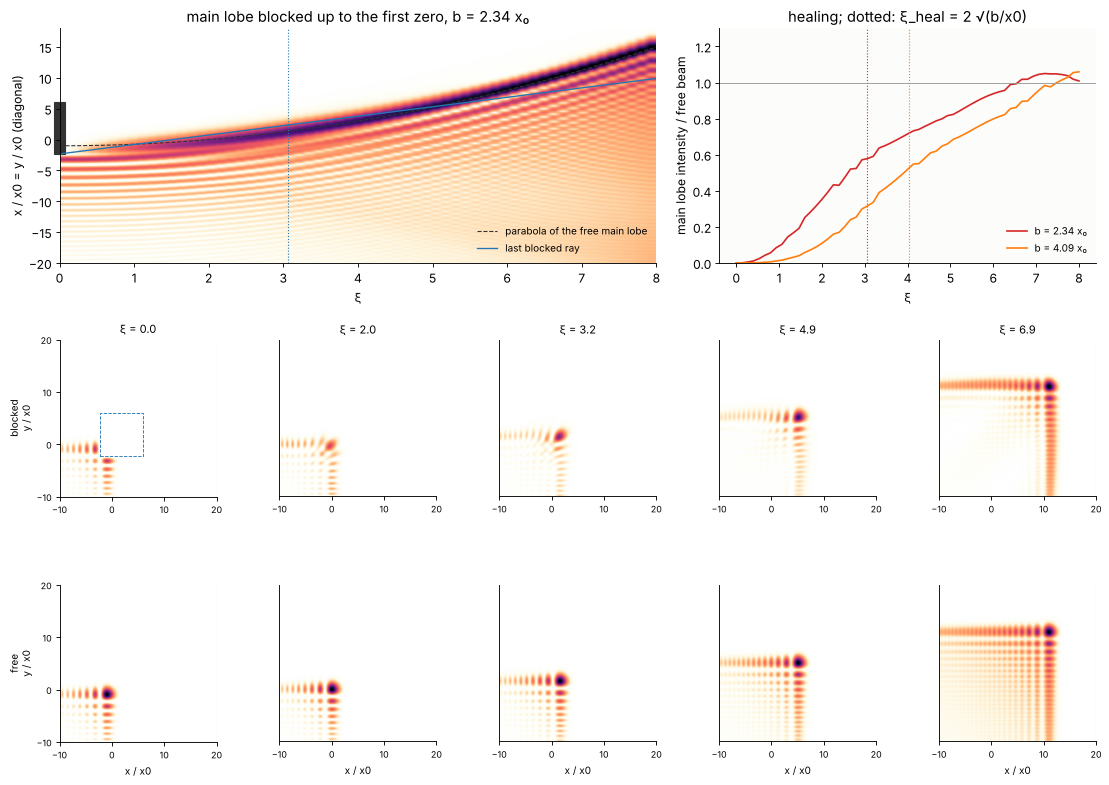

In [15]:
b1 = zeros_ai[0]
xz_s, full_s, _ = results[b1]
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(3, 5, height_ratios=(1.3, 1, 1))
ax = fig.add_subplot(gs[0, :3])
ax.imshow((xz_s/norm_planes).T, extent=(xis[0], xis[-1], s_d[0], s_d[-1]), aspect="auto",
          origin="lower", cmap=LIGHT, norm=PowerNorm(0.5, vmin=0, vmax=1))
ax.plot(xi_f, xi_f**2/4 + s1, "--", color="0.2", lw=1, label="parabola of the free main lobe")
ax.plot(xi_f, -b1 + np.sqrt(b1)*xi_f, color="C0", lw=1.2, label="last blocked ray")
ax.axvline(2*np.sqrt(b1), color="C0", ls=":", lw=1)
ax.add_patch(plt.Rectangle((-0.08, -b1), 0.16, 6 + b1, color="0.2", clip_on=False))
ax.set_ylim(-20, 18)
ax.set_xlabel("ξ")
ax.set_ylabel("x / x0 = y / x0 (diagonal)")
ax.set_title("main lobe blocked up to the first zero, b = 2.34 x₀")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax2 = fig.add_subplot(gs[0, 3:])
for (b, res), col in zip(results.items(), ("C3", "C1")):
    ax2.plot(xis, res[2], color=col, label="b = {:.2f} x₀".format(b))
    ax2.axvline(2*np.sqrt(b), color=col, ls=":", lw=1)
ax2.axhline(1, color="0.6", lw=0.8)
ax2.set_xlabel("ξ")
ax2.set_ylabel("main lobe intensity / free beam")
ax2.set_ylim(0, 1.3)
ax2.set_title("healing; dotted: ξ_heal = 2 √(b/x0)")
ax2.legend(frameon=False, fontsize=9, loc="lower right")
s_win = s_d[win_a]
ext = (s_win[0], s_win[-1], s_win[0], s_win[-1])
for j, i in enumerate(snap_a):
    vmax = np.abs(full_a[i]).max()**2       # each plane to the peak of the free beam
    for k, (full, name) in enumerate(((full_s, "blocked"), (full_a, "free"))):
        a = fig.add_subplot(gs[1 + k, j])
        a.imshow(np.abs(full[i])**2, extent=ext, origin="lower", cmap=LIGHT, vmin=0, vmax=vmax)
        a.tick_params(labelsize=8)
        a.set_xticks([-10, 0, 10, 20])
        a.set_yticks([-10, 0, 10, 20] if j == 0 else [])
        if k == 0:
            a.set_title("ξ = {:.1f}".format(xis[i]), fontsize=10)
            if j == 0:
                a.add_patch(plt.Rectangle((-b1, -b1), 6 + b1, 6 + b1, fill=False, ls="--",
                                          color="C0", lw=0.8))
        if j == 0:
            a.set_ylabel(name + "\ny / x0", fontsize=9)
        if k == 1:
            a.set_xlabel("x / x0", fontsize=9)
plt.tight_layout()
plt.show()

The blocked beam starts with a hole where the main lobe was, while the
side lobes along the two edges keep running as before. Their rays reach
the parabola again, and the main lobe is rebuilt in the corner of the
pattern. As for the Bessel beam, the ray estimate $\xi_{\rm heal}$ marks
the middle of the transition (right, dotted), where the main lobe has
about half of its intensity back, and the healing is complete at about
twice that distance. The transition is gradual because the part that the
obstacle took away is itself a small beam, a few $x_0$ wide, which
diffracts and drifts behind the main lobe only slowly; the ray picture
ignores that. The larger obstacle heals later, as predicted.

## Summary

- A **Bessel beam** is a cone of plane waves at the angle $\theta$; an
  axicon makes one in the diamond-shaped zone $z < w/\tan\theta$. Its
  central lobe, $J_0^2(k\sin\theta\,r)$, keeps its size over the whole
  zone, here 47 times the Rayleigh range of a Gaussian beam with the same
  spot. The on-axis intensity follows the stationary phase result $2\pi
  k\sin^2\theta\,z|A(z\tan\theta)|^2$.
- The price is power: every ring carries about as much as the central
  lobe, which holds about 7 % of it here.
- An obstacle of radius $a$ in the Bessel zone casts a geometric shadow
  of length $a/\tan\theta$; behind it the beam is rebuilt by the light
  that passed beside the obstacle. Half of the central lobe is back at
  the end of the shadow, all of it after about twice that distance.
- An **Airy beam** is the Fourier transform of a Gaussian with a cubic
  phase. Its main lobe runs on the parabola $x = x_0\xi^2/4$, the caustic
  of a family of straight rays, while the centroid of its intensity does
  not move at all. The angular spectrum propagation agrees with the exact
  solution of the paraxial wave equation.
- Blocking the main lobe up to $x = -b$ removes the rays that touch the
  caustic before $\xi_{\rm heal} = 2\sqrt{b/x_0}$; there the main lobe is
  half back, and whole at about twice the distance.
- Both beams heal for the same reason: the light that makes the spot
  further on is not in the spot now, but beside it.

## References

- J. Durnin, "Exact solutions for nondiffracting beams. I. The scalar theory", J. Opt. Soc. Am. A 4, 651-654 (1987).
- J. Durnin, J. J. Miceli and J. H. Eberly, "Diffraction-free beams", Phys. Rev. Lett. 58, 1499-1501 (1987).
- J. H. McLeod, "The axicon: a new type of optical element", J. Opt. Soc. Am. 44, 592-597 (1954).
- F. Gori, G. Guattari and C. Padovani, "Bessel-Gauss beams", Opt. Commun. 64, 491-495 (1987).
- R. M. Herman and T. A. Wiggins, "Production and uses of diffractionless beams", J. Opt. Soc. Am. A 8, 932-942 (1991).
- Z. Bouchal, J. Wagner and M. Chlup, "Self-reconstruction of a distorted nondiffracting beam", Opt. Commun. 151, 207-211 (1998).
- D. McGloin and K. Dholakia, "Bessel beams: diffraction in a new light", Contemp. Phys. 46, 15-28 (2005).
- F. O. Fahrbach, P. Simon and A. Rohrbach, "Microscopy with self-reconstructing beams", Nat. Photonics 4, 780-785 (2010).
- M. V. Berry and N. L. Balazs, "Nonspreading wave packets", Am. J. Phys. 47, 264-267 (1979).
- G. A. Siviloglou and D. N. Christodoulides, "Accelerating finite energy Airy beams", Opt. Lett. 32, 979-981 (2007).
- G. A. Siviloglou, J. Broky, A. Dogariu and D. N. Christodoulides, "Observation of accelerating Airy beams", Phys. Rev. Lett. 99, 213901 (2007).
- J. Broky, G. A. Siviloglou, A. Dogariu and D. N. Christodoulides, "Self-healing properties of optical Airy beams", Opt. Express 16, 12880-12891 (2008).
- P. Polynkin, M. Kolesik, J. V. Moloney, G. A. Siviloglou and D. N. Christodoulides, "Curved plasma channel generation using ultraintense Airy beams", Science 324, 229-232 (2009).
- T. Vettenburg et al., "Light-sheet microscopy using an Airy beam", Nat. Methods 11, 541-544 (2014).

In [16]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 129 s
